# Investigación Operativa — Laboratorio 0 · Solución docente
## De una formulación matemática a una recomendación reproducible

**Clase 01 · Licenciatura en Ciencia de Datos · Universidad Austral**

Caso didáctico simulado. Resultado de referencia: $x_T=20$, $x_M=30$, $z=3800$ puntos.

## Consigna del taller del martes

### Situación problemática

Un equipo de analítica planifica su producción para la próxima semana. Puede entregar **tableros operativos** y **modelos predictivos**. Cada unidad genera puntos de valor, pero consume horas de CPU, GPU y trabajo de analista. La dirección necesita una recomendación cuantitativa que sea factible, verificable y comprensible; no alcanza con informar lo que devuelve un solver.

El archivo `../Datos/caso_capacidad_analitica.csv` contiene los coeficientes del caso. Los datos son simulados y las variables se modelarán inicialmente como continuas.

### Encargo

Determine cuántas unidades semanales de cada servicio conviene producir para maximizar el valor total. Identifique qué recursos limitan la decisión y analice si una modificación de la capacidad de CPU cambia la recomendación.

### Trabajo obligatorio

1. Identifique decisor, horizonte, variables, unidades, objetivo, restricciones y al menos un supuesto que deba validarse.
2. Audite el CSV y construya el modelo lineal sin copiar coeficientes de la salida del solver.
3. Resuelva con HiGHS, registre el estado antes de leer la solución y verifique independientemente no negatividad, consumos, holguras, violación máxima y objetivo.
4. Represente la región factible y marque la solución; el gráfico debe usar las mismas unidades y coeficientes que el modelo.
5. Evalúe las cuatro políticas propuestas y explique por qué una alternativa de gran valor aparente puede ser inadmisible.
6. Reoptimice para 65, 80 y 90 horas de CPU e interprete los cambios y las restricciones activas.

### Entregables

- Notebook ejecutada de principio a fin, sin errores y con controles automáticos aprobados.
- Tabla de decisión, tabla de uso de recursos, gráfico del conjunto factible y tabla de escenarios.
- Recomendación ejecutiva de 120 a 180 palabras y respuestas individuales del *exit ticket*.

### Criterios de aceptación

La entrega debe conservar unidades, declarar la tolerancia numérica, distinguir solución computacional de modelo validado y conectar cada afirmación con evidencia reproducible. Una captura de pantalla o la salida sin interpretar del solver no constituyen una respuesta.

## Hoja de ruta del taller — 120 minutos

| Minutos | Trabajo | Evidencia mínima |
|---:|---|---|
| 0–10 | Recuperar conceptos y anticipar el resultado | Hipótesis escrita antes de ejecutar |
| 10–25 | Auditar datos, unidades y supuestos | Controles de entrada visibles |
| 25–60 | Construir y resolver el caso base | Estado, solución y valor |
| 60–80 | Verificar por una vía independiente | Violación/error y prueba de consistencia |
| 80–105 | Extender o perturbar el caso | Tabla o gráfico comparativo |
| 105–115 | Auditoría cruzada | Lista de observaciones corregidas |
| 115–120 | Recomendación individual | Decisión, evidencia, límite y próximo dato |

**Regla de trabajo.** Si el resultado contradice la anticipación, no se modifica el código hasta escribir una explicación posible y un control que permita distinguir entre error y fenómeno real.

## Preparación individual — 10 minutos

Sin ejecutar código, anticipe la solución del caso de capacidad analítica. Indique qué dos restricciones espera activas, proponga un punto factible y otro inviable, y escriba el control independiente que detectaría un intercambio accidental entre las columnas CPU y GPU.

### Respuesta orientativa

Se espera que GPU y analista sean activas: $x_M=30$ y $x_T+x_M=50$ conducen a $(20,30)$. Un punto factible es $(20,20)$; uno inviable es $(25,30)$ porque requiere 55 horas de analista. Para detectar columnas intercambiadas se recalculan consumos desde una tabla etiquetada: CPU $=2x_T+x_M$, GPU $=2x_M$ y analista $=x_T+x_M$; además se contrastan nombres, unidades y orden de columnas antes de construir matrices.

## Ficha cerrada de datos y supuestos

- Horizonte: una semana; variables continuas y no negativas.
- Tablero operativo: valor 40 puntos; consume 2 h de CPU, 0 h de GPU y 1 h de analista.
- Modelo predictivo: valor 100 puntos; consume 1 h de CPU, 2 h de GPU y 1 h de analista.
- Capacidades: 80 h de CPU, 60 h de GPU y 50 h de analista.
- Objetivo: maximizar puntos de valor semanal. Los coeficientes también están en `../Datos/caso_capacidad_analitica.csv`.
- Supuesto: existe demanda para toda unidad recomendada y los consumos son proporcionales.

## 0. Ficha decisional

- **Decisor:** responsable del equipo analítico.
- **Horizonte:** una semana.
- **Variables:** unidades semanales de tableros y modelos.
- **Audiencia:** dirección del área y responsables de capacidad.
- **Supuesto crítico:** los puntos de valor y consumos unitarios son representativos y constantes.

In [1]:
from pathlib import Path
import platform

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy
from scipy.optimize import linprog

print("Python:", platform.python_version())
print("NumPy:", np.__version__)
print("pandas:", pd.__version__)
print("SciPy:", scipy.__version__)

Python: 3.12.13
NumPy: 2.5.1
pandas: 3.0.5
SciPy: 1.18.0


## 1. Datos y controles

In [2]:
DATA = Path("../Datos/caso_capacidad_analitica.csv")
df = pd.read_csv(DATA)
df

,servicio,valor_por_unidad,horas_cpu,horas_gpu,horas_analista
0,Tablero operativo,40.0,2,0,1
1,Modelo predictivo,100.0,1,2,1
2,capacidad_disponible,NaN,80,60,50


In [3]:
servicios = df.iloc[:2].copy()
capacidades = df.iloc[2][["horas_cpu", "horas_gpu", "horas_analista"]].astype(float)

coef_cols = ["valor_por_unidad", "horas_cpu", "horas_gpu", "horas_analista"]
assert servicios[coef_cols].notna().all().all()
assert (servicios[coef_cols] >= 0).all().all()
assert (capacidades > 0).all()

servicios, capacidades

(            servicio  valor_por_unidad  horas_cpu  horas_gpu  horas_analista
0  Tablero operativo              40.0          2          0               1
1  Modelo predictivo             100.0          1          2               1, horas_cpu         80.0
horas_gpu         60.0
horas_analista    50.0
Name: 2, dtype: float64)

## 2. Formulación y solución

`linprog` minimiza; se pasa el negativo del vector de valor para representar la maximización.

In [4]:
c_max = servicios["valor_por_unidad"].to_numpy(dtype=float)
A_ub = np.array([
    servicios["horas_cpu"].to_numpy(dtype=float),
    servicios["horas_gpu"].to_numpy(dtype=float),
    servicios["horas_analista"].to_numpy(dtype=float),
])
b_ub = capacidades.to_numpy(dtype=float)
bounds = [(0, None), (0, None)]

resultado = linprog(
    c=-c_max,
    A_ub=A_ub,
    b_ub=b_ub,
    bounds=bounds,
    method="highs",
)

{
    "success": resultado.success,
    "status": resultado.status,
    "message": resultado.message,
    "x": resultado.x,
    "valor": -resultado.fun,
}

{'success': True, 'status': 0, 'message': 'Optimization terminated successfully. (HiGHS Status 7: Optimal)', 'x': array([20., 30.]), 'valor': 3800.0}

## 3. Verificación independiente

In [5]:
def verificar_solucion(x, A, b, c, tol=1e-7):
    x = np.asarray(x, dtype=float)
    consumos = A @ x
    holguras = b - consumos
    violaciones = np.maximum(consumos - b, 0.0)
    no_negatividad = bool(np.all(x >= -tol))
    factible = bool(no_negatividad and np.max(violaciones, initial=0.0) <= tol)
    return {
        "factible": factible,
        "no_negatividad": no_negatividad,
        "consumos": consumos,
        "holguras": holguras,
        "violacion_max": float(np.max(violaciones, initial=0.0)),
        "valor_recalculado": float(c @ x),
    }

verificacion = verificar_solucion(resultado.x, A_ub, b_ub, c_max)
verificacion

{'factible': True, 'no_negatividad': True, 'consumos': array([70., 60., 50.]), 'holguras': array([10.,  0.,  0.]), 'violacion_max': 0.0, 'valor_recalculado': 3800.0}

In [6]:
assert resultado.success
assert verificacion["factible"]
assert np.allclose(resultado.x, [20.0, 30.0], atol=1e-7)
assert np.isclose(verificacion["valor_recalculado"], 3800.0)
assert np.allclose(verificacion["holguras"], [10.0, 0.0, 0.0], atol=1e-7)
print("Controles aprobados.")

Controles aprobados.


## 4. Interpretación de variables y recursos

In [7]:
decision = pd.DataFrame({
    "variable": ["x_T", "x_M"],
    "servicio": servicios["servicio"],
    "valor_optimo": resultado.x,
    "unidad": "unidades/semana",
})

recursos = pd.DataFrame({
    "recurso": ["CPU", "GPU", "Analista"],
    "capacidad_h": b_ub,
    "consumo_h": verificacion["consumos"],
    "holgura_h": verificacion["holguras"],
})
recursos["activa"] = np.isclose(recursos["holgura_h"], 0.0, atol=1e-7)

decision, recursos

(  variable           servicio  valor_optimo           unidad
0      x_T  Tablero operativo          20.0  unidades/semana
1      x_M  Modelo predictivo          30.0  unidades/semana,     recurso  capacidad_h  consumo_h  holgura_h  activa
0       CPU         80.0       70.0       10.0   False
1       GPU         60.0       60.0        0.0    True
2  Analista         50.0       50.0        0.0    True)

## 5. Visualización geométrica

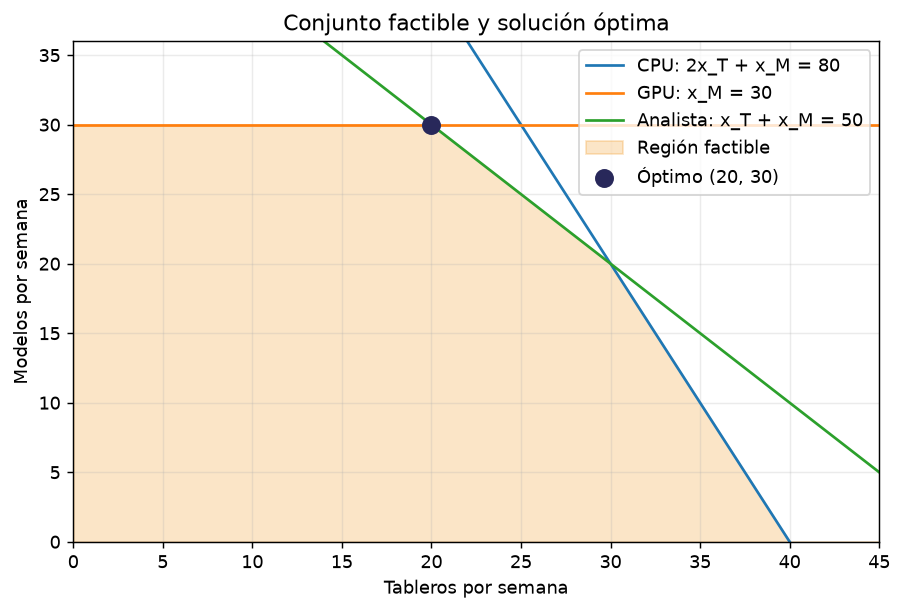

In [8]:
x_t = np.linspace(0, 45, 600)
y_cpu = 80 - 2*x_t
y_gpu = np.full_like(x_t, 30.0)
y_analista = 50 - x_t
y_factible = np.minimum.reduce([y_cpu, y_gpu, y_analista])
y_factible = np.clip(y_factible, 0, None)

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(x_t, y_cpu, label="CPU: 2x_T + x_M = 80")
ax.plot(x_t, y_gpu, label="GPU: x_M = 30")
ax.plot(x_t, y_analista, label="Analista: x_T + x_M = 50")
ax.fill_between(x_t, 0, y_factible, alpha=0.22, color="#F08A00", label="Región factible")
ax.scatter(*resultado.x, color="#28285A", s=90, zorder=5, label="Óptimo (20, 30)")
ax.set(xlim=(0, 45), ylim=(0, 36), xlabel="Tableros por semana", ylabel="Modelos por semana")
ax.grid(alpha=0.25)
ax.legend(loc="upper right")
ax.set_title("Conjunto factible y solución óptima")
plt.show()

## 6. Comparación de políticas

In [9]:
politicas = {
    "A": np.array([20.0, 20.0]),
    "B": np.array([40.0, 0.0]),
    "C": np.array([25.0, 30.0]),
    "D": np.array([20.0, 30.0]),
}

filas = []
for nombre, x in politicas.items():
    v = verificar_solucion(x, A_ub, b_ub, c_max)
    filas.append({
        "politica": nombre,
        "x_T": x[0],
        "x_M": x[1],
        "factible": v["factible"],
        "valor": v["valor_recalculado"],
        "violacion_max_h": v["violacion_max"],
    })

pd.DataFrame(filas)

,politica,x_T,x_M,factible,valor,violacion_max_h
0,A,20.0,20.0,True,2800.0,0.0
1,B,40.0,0.0,True,1600.0,0.0
2,C,25.0,30.0,False,4000.0,5.0
3,D,20.0,30.0,True,3800.0,0.0


La política C presenta el valor aparente más alto, 4000 puntos, pero viola en 5 horas la capacidad de analista. D es factible y coincide con la solución óptima certificada.

## 7. Experimento con capacidad de CPU

In [10]:
def resolver(cap_cpu):
    b = b_ub.copy()
    b[0] = cap_cpu
    r = linprog(c=-c_max, A_ub=A_ub, b_ub=b, bounds=bounds, method="highs")
    if not r.success:
        return {"cpu": cap_cpu, "success": False, "status": r.message}
    v = verificar_solucion(r.x, A_ub, b, c_max)
    return {
        "cpu": cap_cpu,
        "success": True,
        "x_T": r.x[0],
        "x_M": r.x[1],
        "valor": v["valor_recalculado"],
        "holgura_cpu": v["holguras"][0],
    }

escenarios = pd.DataFrame([resolver(cap) for cap in [65, 80, 90]])
escenarios

,cpu,success,x_T,x_M,valor,holgura_cpu
0,65,True,17.5,30.0,3700.0,0.0
1,80,True,20.0,30.0,3800.0,10.0
2,90,True,20.0,30.0,3800.0,20.0


Con 90 horas de CPU, la decisión no cambia porque el modelo base ya tenía 10 horas de holgura. Con 65 horas, CPU pasa a limitar y el óptimo cambia. La observación anticipa el análisis de sensibilidad, aunque todavía no calcula precios sombra ni rangos de validez.

## 8. Recomendación ejecutiva de referencia

Para la próxima semana se recomienda planificar **20 tableros operativos y 30 modelos predictivos**, combinación que maximiza el valor modelado en **3800 puntos semanales**. La solución utiliza completamente las 60 horas de GPU y las 50 horas de analista, mientras conserva 10 horas de CPU. Por lo tanto, ampliar CPU hasta 90 horas no mejora la decisión bajo los demás supuestos; GPU y capacidad de analista son los límites inmediatos. La recomendación está condicionada a que exista demanda para ambas cantidades y a que los valores y tiempos unitarios sean representativos. El modelo tampoco incorpora variabilidad, retrabajo, mantenibilidad ni exigencia de unidades enteras. Antes de implementarlo, se debería validar la demanda y contrastar los consumos unitarios con registros históricos, además de analizar escenarios de incertidumbre.

## 9. Exit ticket — respuestas esperadas

1. `success` indica que el algoritmo terminó satisfactoriamente para el modelo computacional; no prueba que datos, objetivo o restricciones representen la decisión real.
2. El control dimensional detecta sumas o comparaciones entre magnitudes incompatibles, algo que el solver trata como números sin significado.
3. Debe cambiar el dominio a variables enteras y utilizarse un método de programación entera; no alcanza con redondear la solución continua sin verificar.

## Alternativas de resolución para la puesta en común

La solución principal con HiGHS ya fue desarrollada. Las dos rutas siguientes resuelven el mismo LP sin leer `resultado.x`; deben coincidir en `(20,30)` y 3800. Después se cierra el caso de publicidad y retención planteado en las diapositivas.

### Alternativa 2 — enumeración exacta de vértices

In [11]:
from itertools import combinations

def vertices_lp_2d(A, b, tol=1e-9):
    A = np.asarray(A, float); b = np.asarray(b, float)
    fronteras_A = np.vstack([A, -np.eye(2)])
    fronteras_b = np.r_[b, 0.0, 0.0]
    vertices = []
    for i, j in combinations(range(len(fronteras_b)), 2):
        M = fronteras_A[[i, j]]
        if np.linalg.matrix_rank(M) < 2:
            continue
        x = np.linalg.solve(M, fronteras_b[[i, j]])
        if (A @ x <= b + tol).all() and (x >= -tol).all():
            vertices.append(x)
    return np.unique(np.round(vertices, 10), axis=0)

vertices_analitica = vertices_lp_2d(A_ub, b_ub)
valores_vertices = vertices_analitica @ c_max
x_vertices = vertices_analitica[np.argmax(valores_vertices)]
assert np.allclose(x_vertices, resultado.x)
pd.DataFrame(vertices_analitica, columns=["x_T", "x_M"]).assign(valor=valores_vertices)

,x_T,x_M,valor
0,-0.0,-0.0,0.0
1,-0.0,30.0,3000.0
2,20.0,30.0,3800.0
3,30.0,20.0,3200.0
4,40.0,-0.0,1600.0


### Alternativa 3 — malla vectorizada como oráculo aproximado

In [12]:
paso = 0.25
eje = np.arange(0, 50 + paso, paso)
XT, XM = np.meshgrid(eje, eje, indexing="ij")
candidatos = np.c_[XT.ravel(), XM.ravel()]
mascara = (candidatos @ A_ub.T <= b_ub + 1e-9).all(axis=1)
factibles_malla = candidatos[mascara]
x_malla = factibles_malla[np.argmax(factibles_malla @ c_max)]
assert np.allclose(x_malla, resultado.x)
pd.DataFrame([
    {"método": "HiGHS", "x_T": resultado.x[0], "x_M": resultado.x[1], "valor": -resultado.fun},
    {"método": "vértices", "x_T": x_vertices[0], "x_M": x_vertices[1], "valor": c_max @ x_vertices},
    {"método": "malla 0,25", "x_T": x_malla[0], "x_M": x_malla[1], "valor": c_max @ x_malla},
])

,método,x_T,x_M,valor
0,HiGHS,20.0,30.0,3800.0
1,vértices,20.0,30.0,3800.0
2,"malla 0,25",20.0,30.0,3800.0


## Caso puente completo — publicidad digital y retención

La organización dispone de 100 mil dólares mensuales. Sean $x_P$ y $x_R$ miles de dólares destinados a publicidad y retención. Cada mil invertido aporta respectivamente 8 y 5 puntos esperados y demanda 0,4 y 0,1 horas de revisión legal. Hay 25 horas legales; se exige $x_R\ge20$ y $x_P\le70$. Las variables son continuas y no negativas.

Se maximiza $8x_P+5x_R$ sujeto a presupuesto, revisión legal y reglas estratégicas.

In [13]:
c_pr = np.array([8.0, 5.0])
A_pr = np.array([[1.0, 1.0], [0.4, 0.1], [1.0, 0.0], [0.0, -1.0]])
b_pr = np.array([100.0, 25.0, 70.0, -20.0])
r_pr = linprog(-c_pr, A_ub=A_pr, b_ub=b_pr, bounds=[(0, None)]*2, method="highs")
v_pr = vertices_lp_2d(A_pr, b_pr)
x_pr_vertices = v_pr[np.argmax(v_pr @ c_pr)]
eje_pr = np.arange(0, 101, 1.0)
XP, XR = np.meshgrid(eje_pr, eje_pr, indexing="ij")
grid_pr = np.c_[XP.ravel(), XR.ravel()]
grid_pr = grid_pr[(grid_pr @ A_pr.T <= b_pr + 1e-9).all(axis=1)]
x_pr_grid = grid_pr[np.argmax(grid_pr @ c_pr)]
assert r_pr.success and np.allclose(r_pr.x, [50, 50])
assert np.allclose(r_pr.x, x_pr_vertices) and np.allclose(r_pr.x, x_pr_grid)
pd.DataFrame([
    {"método": "HiGHS", "publicidad_miles": r_pr.x[0], "retención_miles": r_pr.x[1], "valor": -r_pr.fun},
    {"método": "vértices", "publicidad_miles": x_pr_vertices[0], "retención_miles": x_pr_vertices[1], "valor": c_pr @ x_pr_vertices},
    {"método": "malla de 1.000 USD", "publicidad_miles": x_pr_grid[0], "retención_miles": x_pr_grid[1], "valor": c_pr @ x_pr_grid},
])

,método,publicidad_miles,retención_miles,valor
0,HiGHS,50.0,50.0,650.0
1,vértices,50.0,50.0,650.0
2,malla de 1.000 USD,50.0,50.0,650.0


**Lectura docente.** Las tres rutas dan 50 mil dólares en publicidad y 50 mil en retención, con 650 puntos. Presupuesto y revisión legal quedan activos: `50+50=100` y `0.4·50+0.1·50=25`. El mínimo de retención y el máximo de publicidad no quedan activos.

## Respuesta integral a la consigna

1. **Ficha decisional.** El responsable del equipo analítico decide, para una semana, cuántos tableros y modelos producir. Las variables son unidades/semana; el objetivo maximiza puntos semanales y las capacidades se expresan en horas. El supuesto crítico es que valores, consumos y demanda son constantes en el horizonte.
2. **Auditoría y modelo.** El CSV contiene dos servicios y una fila de capacidades. El modelo maximiza $40x_T+100x_M$ sujeto a CPU $2x_T+x_M\le80$, GPU $2x_M\le60$, analista $x_T+x_M\le50$ y no negatividad.
3. **Solución y verificación.** HiGHS termina en estado óptimo con $(x_T,x_M)=(20,30)$ y valor 3800. Los consumos son $(70,60,50)$ h, las holguras $(10,0,0)$ h y la violación máxima es 0. El objetivo fue recalculado fuera del objeto del solver.
4. **Geometría.** La solución se ubica en la intersección de GPU y analista; la región y el punto usan los mismos coeficientes que el modelo.
5. **Políticas.** A $(20,20)$ vale 2800 y es factible; B $(40,0)$ vale 1600 y es factible; C $(25,30)$ parece valer 4000, pero viola analista en 5 h; D $(20,30)$ es factible y óptima.
6. **Escenarios de CPU.** Con 65 h, el óptimo es $(17{,}5,30)$ y vale 3700; con 80 h es $(20,30)$ y vale 3800; con 90 h no cambia y sobran 20 h. GPU y analista, no CPU adicional, limitan el caso base.

**Recomendación.** Planificar 20 tableros y 30 modelos. La decisión está certificada para el LP y usa por completo GPU y analistas. Antes de implementarla deben validarse demanda, divisibilidad y variabilidad de consumos. El caso puente publicidad-retención también queda cerrado: las tres rutas coinciden en 50/50 y 650 puntos; presupuesto y revisión legal están activos.

## Extensión guiada — 25 minutos

Extienda el caso de capacidad analítica incorporando una exigencia de al menos 10 tableros, $x_T\ge10$. Resuelva nuevamente, compare con el caso base, verifique todas las restricciones y explique si la nueva regla cambia la decisión, el valor o sólo la descripción del conjunto factible.

### Solución y criterios de corrección

La solución base $(20,30)$ ya cumple $x_T\ge10$, por lo que continúa siendo factible y óptima con $z=3800$. La nueva restricción tiene holgura $20-10=10$ y no modifica ni decisión ni valor; sí elimina del conjunto factible puntos con $x_T<10$, entre ellos $(0,0)$ y $(0,30)$. La conclusión debe apoyarse en reoptimización o en el argumento de inclusión: se quitó sólo una región que no contenía al óptimo base. Si el mínimo superara 20, la recomendación podría cambiar y sería necesario resolver otro escenario.

## Auditoría cruzada — 10 minutos

Intercambie la notebook con otra persona y deje evidencia de estas cinco comprobaciones:

1. los datos usados coinciden con la ficha y conservan unidades;
2. el estado del método se lee antes de interpretar valores;
3. objetivo, restricciones o métricas se recalculan fuera del objeto principal;
4. el gráfico o la tabla responde a la misma versión del modelo;
5. la recomendación distingue resultado, supuesto y límite.

Registre al menos una observación recibida y la modificación realizada.

## Lista de control antes de entregar

- [ ] La pregunta de decisión aparece respondida en una frase.
- [ ] Cada variable y cada métrica tiene unidad y horizonte.
- [ ] El código puede ejecutarse desde el inicio sin intervención manual oculta.
- [ ] Hay evidencia de estado, factibilidad o validez estadística, según corresponda.
- [ ] Se compara al menos un escenario o método alternativo.
- [ ] La recomendación incluye una limitación y el próximo dato necesario.